# Cervical cancer screening data: exploratory analysis

This notebook explores risk-factor patterns and screening outcomes in the public cervical cancer dataset stored in `data/`. It uses **K-Means clustering** to describe groups of records and **association rules** to summarize co-occurring characteristics.

## Who this is for
- **Analysts:** inspect preprocessing, feature construction, cluster selection, and rule metrics in the code cells.
- **Clinicians and other stakeholders:** read the short interpretation notes after each analysis. These describe what the charts show without requiring machine-learning terminology.

## Models and methods used
- **K-Means clustering:** partitions records using all 30 standardized risk-factor input features. The notebook compares 2?5 clusters by silhouette score and uses the best-scoring count (3 for the supplied data). It is unsupervised and does not predict biopsy results.
- **Principal component analysis (PCA):** reduces the standardized inputs to two dimensions for the scatterplot only; it is not the clustering input or a diagnostic model.
- **Apriori association-rule mining:** finds co-occurring binary characteristics and summarizes direct associations with positive biopsy using support, confidence, and lift. These rules are descriptive, not causal or predictive.
- **Preprocessing:** median imputation for missing input features and standard scaling before K-Means and PCA. Screening outcomes are not used as clustering features and are not imputed.

No supervised classifier or validated clinical prediction model is trained in this project.

## Important clinical context
This is an exploratory analysis of a historical public dataset. A cluster is **not** a clinical risk category, and an association is **not** evidence that a factor causes a biopsy result. The analysis does not diagnose cancer, estimate an individual's risk, recommend screening, or replace clinical judgment. Small groups and missing data can make percentages unstable.

## Workflow
1. Load the dataset and review its shape and missingness.
2. Impute missing **input features** and standardize them for clustering; leave screening outcomes unchanged.
3. Compare candidate cluster counts, then inspect a two-dimensional PCA view.
4. Compare observed biopsy and Schiller positivity across the exploratory groups.
5. Review simple co-occurrence rules for positive biopsy, with prevalence and interpretation limits.

Run the notebook from the project root or the `notebooks/` folder. Install dependencies with `pip install -r requirements.txt`.

In [43]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

COLORS = {
    "rose": "#C2185B",
    "coral": "#E45756",
    "orange": "#F4A261",
    "blush": "#F7CAD0",
    "ink": "#4A2634",
    "grid": "#EADDE1",
}
CLUSTER_PALETTE = [COLORS["rose"], COLORS["coral"], COLORS["orange"], "#A23B72", "#F6BD60"]

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.titleweight": "bold",
    "axes.labelcolor": COLORS["ink"],
    "text.color": COLORS["ink"],
    "axes.edgecolor": COLORS["grid"],
    "grid.color": COLORS["grid"],
})

# Support running from either the project root or the notebooks folder.
cwd = Path.cwd()
if (cwd / "data" / "kag_risk_factors_cervical_cancer.csv").is_file():
    project_root = cwd
elif (cwd.parent / "data" / "kag_risk_factors_cervical_cancer.csv").is_file():
    project_root = cwd.parent
else:
    raise FileNotFoundError(
        "Could not find data/kag_risk_factors_cervical_cancer.csv from the "
        "current folder. Run this notebook from the project root or notebooks/."
    )

data_path = project_root / "data" / "kag_risk_factors_cervical_cancer.csv"
output_dir = project_root / "outputs"
df = pd.read_csv(data_path, na_values=["?"])

print(f"Dataset loaded: {len(df):,} records and {df.shape[1]} columns")
print(f"Columns containing missing values: {int(df.isna().any().sum())}")
display(df.head())

Dataset loaded: 858 records and 36 columns
Columns containing missing values: 26


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy
0,18,4.0,15.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
1,15,1.0,14.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
2,34,1.0,NaN,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
3,52,5.0,16.0,4.0,1.0,37.0,37.0,1.0,3.0,0.0,...,NaN,NaN,1,0,1,0,0,0,0,0
4,46,3.0,21.0,4.0,0.0,0.0,0.0,1.0,15.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0


## 1. Prepare the model inputs

The four screening tests are treated as **outcomes**, not as model inputs. Missing values in risk-factor inputs are filled with each column's median so K-Means can run; missing biopsy results stay unknown and are not counted as negative. Standardization puts numeric columns on comparable scales before clustering.

In [44]:
# Remove two very sparse timeline fields and convert all remaining values to numeric.
drop_cols = [
    "STDs: Time since first diagnosis",
    "STDs: Time since last diagnosis",
]
df_clean = df.drop(columns=[col for col in drop_cols if col in df.columns]).apply(
    pd.to_numeric, errors="coerce"
)

target_cols = ["Hinselmann", "Schiller", "Citology", "Biopsy"]
missing_targets = [col for col in target_cols if col not in df_clean.columns]
if missing_targets:
    raise ValueError(f"Expected screening outcome columns are missing: {missing_targets}")
feature_cols = [col for col in df_clean.columns if col not in target_cols]

# Fill only the model inputs; never turn an unknown screening result into a negative.
imputer = SimpleImputer(strategy="median")
df_imputed = df_clean.copy()
df_imputed[feature_cols] = imputer.fit_transform(df_clean[feature_cols])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_imputed[feature_cols])
missing_feature_values = int(df_clean[feature_cols].isna().sum().sum())
missing_biopsy_values = int(df_clean["Biopsy"].isna().sum())
print(f"Input features: {len(feature_cols)}; missing feature values imputed: {missing_feature_values}")
print(f"Records with an unknown biopsy result (kept unknown): {missing_biopsy_values}")
print(f"Standardized model input shape: {X_scaled.shape}")

Input features: 30; missing feature values imputed: 2048
Records with an unknown biopsy result (kept unknown): 0
Standardized model input shape: (858, 30)


## 2. Compare cluster counts

The silhouette score summarizes how close each record is to its own group compared with other groups; higher is better within this small candidate range. The selected count is a convenient exploratory partition, not proof that these are natural or medically distinct patient types.

In [45]:
# Compare a small, prespecified range of cluster counts using silhouette score.
silhouette_results = []
for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    silhouette_results.append({
        "Clusters (k)": k,
        "Silhouette score": silhouette_score(X_scaled, labels),
    })

silhouette_results = pd.DataFrame(silhouette_results)
best_k = int(silhouette_results.loc[silhouette_results["Silhouette score"].idxmax(), "Clusters (k)"])
display(silhouette_results.style.format({"Silhouette score": "{:.3f}"}))
print(f"Selected k={best_k}: it has the highest silhouette score among the tested values (2?5).")

,Clusters (k),Silhouette score
0,2,0.575
1,3,0.582
2,4,0.330
3,5,0.365


Selected k=3: it has the highest silhouette score among the tested values (2?5).


## 3. View the groups in two dimensions

Each dot represents one record. PCA compresses the standardized inputs into two axes for visualization, while K-Means uses all input dimensions. Axes show the share of overall input variation represented; separation in this drawing is not a measure of diagnosis or individual risk.

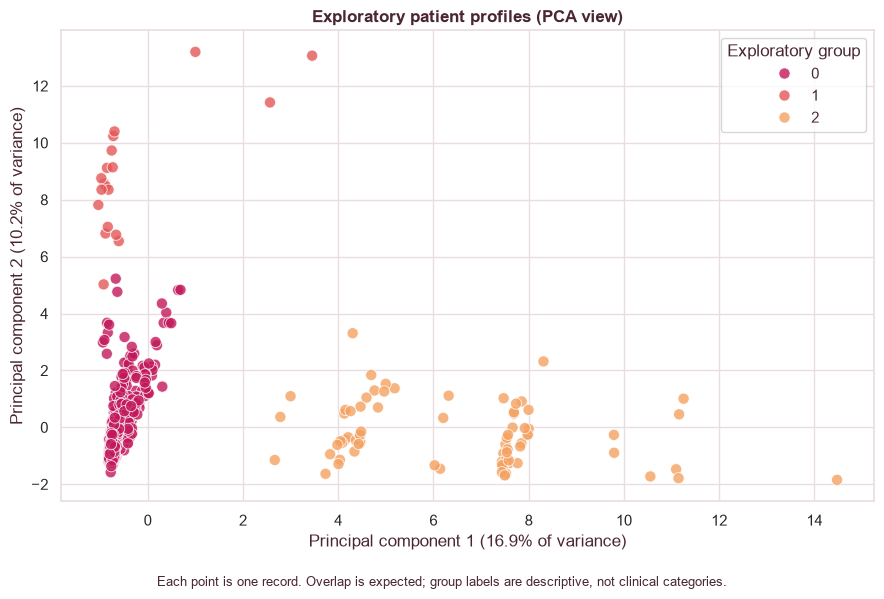

In [46]:
# Fit the selected model on all standardized input features.
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df_imputed["Cluster"] = kmeans.fit_predict(X_scaled)

# PCA is only a two-axis visualization; clustering used the full feature set.
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(X_scaled)
df_imputed["PCA1"] = pca_coords[:, 0]
df_imputed["PCA2"] = pca_coords[:, 1]

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=df_imputed,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    hue_order=list(range(best_k)),
    palette=CLUSTER_PALETTE[:best_k],
    alpha=0.8,
    s=65,
    ax=ax,
)
ax.set_title("Exploratory patient profiles (PCA view)")
ax.set_xlabel(f"Principal component 1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
ax.set_ylabel(f"Principal component 2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
ax.legend(title="Exploratory group")
fig.text(
    0.5, 0.01,
    "Each point is one record. Overlap is expected; group labels are descriptive, not clinical categories.",
    ha="center", fontsize=9, color=COLORS["ink"],
)
fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig(output_dir / "pca_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Describe the groups and screening results

The tables show group sizes and average recorded characteristics. In the charts, a bar is the fraction of records in that group with a recorded positive result; records with an unknown result are omitted from that outcome's average. Compare these as descriptive sample rates, especially cautiously for small groups. Group IDs are arbitrary and have no low-to-high ordering.

Group sizes


,Records,Share of cohort (%)
Exploratory group,,
0,762,88.8%
1,19,2.2%
2,77,9.0%


Average recorded characteristics and observed screening positivity


,Age,Smokes (years),Hormonal Contraceptives (years),IUD (years),STDs,Biopsy positive (%),Schiller positive (%)
Exploratory group,,,,,,,
0,26.6,1.1,2.0,0.4,0.0,4.9,6.8
1,33.2,2.5,3.4,1.6,0.1,31.6,36.8
2,27.3,2.3,2.0,0.6,1.0,15.6,19.5


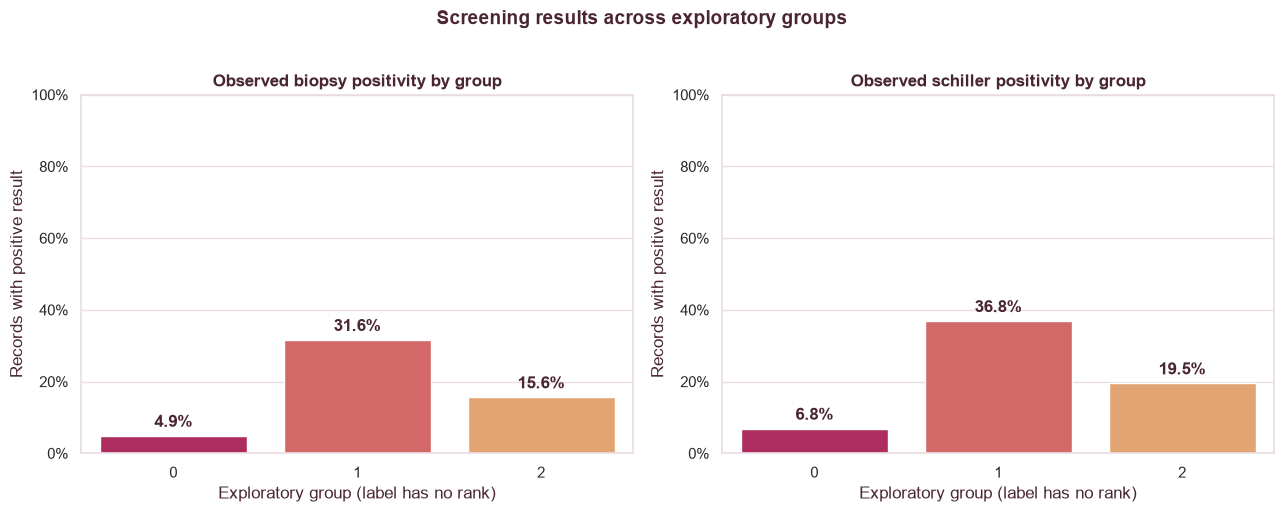

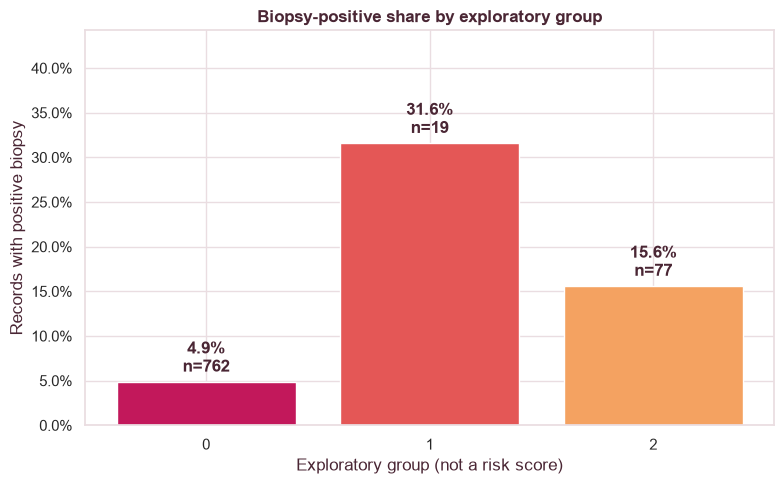

In [47]:
# Summarize group size and average values of selected recorded characteristics.
cluster_sizes = df_imputed.groupby("Cluster").size()
cluster_summary = pd.DataFrame({
    "Records": cluster_sizes,
    "Share of cohort (%)": cluster_sizes / len(df_imputed) * 100,
})
cluster_summary.index.name = "Exploratory group"
print("Group sizes")
display(cluster_summary.style.format({"Share of cohort (%)": "{:.1f}%"}))

profile_features = [
    "Age",
    "Smokes (years)",
    "Hormonal Contraceptives (years)",
    "IUD (years)",
    "STDs",
]
profile_summary = df_imputed.groupby("Cluster")[profile_features].mean()
profile_summary["Biopsy positive (%)"] = df_imputed.groupby("Cluster")["Biopsy"].mean() * 100
profile_summary["Schiller positive (%)"] = df_imputed.groupby("Cluster")["Schiller"].mean() * 100
profile_summary.index.name = "Exploratory group"
print("Average recorded characteristics and observed screening positivity")
display(profile_summary.round(1))

# Compare the observed positivity rates; missing outcomes are excluded from each mean.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, outcome, title in zip(
    axes,
    ["Biopsy", "Schiller"],
    ["Biopsy positivity", "Schiller positivity"],
):
    sns.barplot(
        data=df_imputed,
        x="Cluster",
        y=outcome,
        hue="Cluster",
        hue_order=list(range(best_k)),
        palette=CLUSTER_PALETTE[:best_k],
        errorbar=None,
        ax=ax,
    )
    if ax.legend_:
        ax.legend_.remove()
    ax.set_title(f"Observed {title.lower()} by group")
    ax.set_xlabel("Exploratory group (label has no rank)")
    ax.set_ylabel("Records with positive result")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylim(0, 1)
    for patch in ax.patches:
        rate = patch.get_height()
        if rate > 0:
            ax.annotate(
                f"{rate:.1%}",
                (patch.get_x() + patch.get_width() / 2, rate),
                ha="center",
                va="bottom",
                xytext=(0, 4),
                textcoords="offset points",
                fontweight="bold",
            )

fig.suptitle("Screening results across exploratory groups", y=1.02, fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(output_dir / "cluster_diagnostic_rates.png", dpi=300, bbox_inches="tight")
plt.show()

# Keep the standalone biopsy chart in sync with the notebook's other figure.
biopsy_rates = df_imputed.groupby("Cluster")["Biopsy"].mean()
biopsy_counts = df_imputed.groupby("Cluster")["Biopsy"].count()
fig_biopsy, ax_biopsy = plt.subplots(figsize=(8, 5))
bars = ax_biopsy.bar(
    biopsy_rates.index.astype(str),
    biopsy_rates.values,
    color=CLUSTER_PALETTE[:best_k],
)
ax_biopsy.set_title("Biopsy-positive share by exploratory group")
ax_biopsy.set_xlabel("Exploratory group (not a risk score)")
ax_biopsy.set_ylabel("Records with positive biopsy")
ax_biopsy.yaxis.set_major_formatter(PercentFormatter(1))
ax_biopsy.set_ylim(0, min(1, max(0.1, biopsy_rates.max() * 1.4)))
for position, bar in enumerate(bars):
    rate = bar.get_height()
    count = int(biopsy_counts.iloc[position])
    ax_biopsy.annotate(
        f"{rate:.1%}\nn={count}",
        (bar.get_x() + bar.get_width() / 2, rate),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points",
        fontweight="bold",
    )
fig_biopsy.tight_layout()
fig_biopsy.savefig(output_dir / "biopsy_rate_by_cluster.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Read co-occurrence rules

A rule lists recorded characteristics that co-occurred with a positive biopsy in this dataset. **Support** is the share of all known-biopsy records matching both sides; **biopsy-positive share within group** (confidence) is the share of records matching the listed characteristics that had a positive biopsy; **lift** compares that share with the overall biopsy-positive share (above 1 means higher co-occurrence in this sample). A higher lift can still describe very few records. These are unadjusted associations, not causal effects or clinical predictions.

The horizontal bar chart shows the biopsy-positive share for each displayed rule. **n** beside a bar is the total number of records matching the listed characteristics (the denominator for that share); the dashed line is the overall positive-biopsy rate in the known-result dataset. The table additionally reports support (the count/share matching both sides) and lift. Read the chart as a compact sample summary, not as a causal or individual-risk comparison.

Direct co-occurrence rules for positive biopsy (ranked by lift)


,Recorded characteristics,Group records (n),Support (records),Support (%),Biopsy-positive share within group (%),Lift
31,Recorded STD history,79,12,1.40,15.19,2.37
8,Long-term hormonal contraceptive use (>5 years),114,13,1.52,11.40,1.78
37,IUD use,83,9,1.05,10.84,1.69
87,"Smoker, Smoking history >5 years",68,6,0.70,8.82,1.38
25,Smoking history >5 years,68,6,0.70,8.82,1.38
16,Smoker,123,10,1.17,8.13,1.27
35,More than 3 sexual partners,146,11,1.28,7.53,1.18


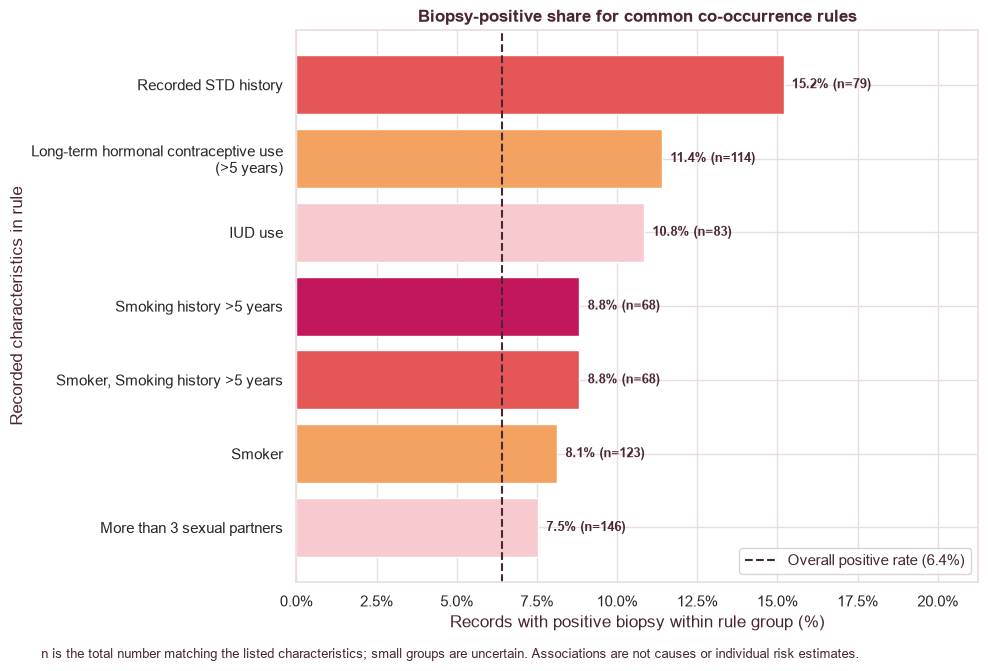

Rules are based on 858 records with a known biopsy result.


In [48]:
import textwrap

# Create transparent, explicitly defined indicators for an exploratory co-occurrence analysis.
df_assoc = pd.DataFrame(index=df_imputed.index)
df_assoc["Long-term hormonal contraceptive use (>5 years)"] = (
    df_imputed["Hormonal Contraceptives (years)"] > 5
)
df_assoc["Smoker"] = df_imputed["Smokes (years)"] > 0
df_assoc["Smoking history >5 years"] = df_imputed["Smokes (years)"] > 5
df_assoc["Recorded STD history"] = df_imputed["STDs"] > 0
df_assoc["More than 3 sexual partners"] = df_imputed["Number of sexual partners"] > 3
df_assoc["IUD use"] = df_imputed["IUD (years)"] > 0
df_assoc["Positive biopsy"] = df_clean["Biopsy"].eq(1)

# Exclude records whose biopsy outcome is unknown instead of treating them as negative.
known_biopsy = df_clean["Biopsy"].notna()
df_assoc = df_assoc.loc[known_biopsy]
frequent_itemsets = apriori(df_assoc, min_support=0.005, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

# Keep only rules whose complete conclusion is a positive biopsy.
positive_biopsy = frozenset({"Positive biopsy"})
target_rules = rules.loc[
    rules["consequents"].apply(lambda items: items == positive_biopsy)
].copy()

target_rules["Recorded characteristics"] = target_rules["antecedents"].apply(
    lambda items: ", ".join(sorted(items))
)
target_rules["Support (records)"] = (target_rules["support"] * len(df_assoc)).round().astype(int)
target_rules["Support (%)"] = target_rules["support"] * 100
target_rules["Biopsy-positive share within group (%)"] = target_rules["confidence"] * 100
# The chart's n is the number of records matching the rule's antecedent,
# which is the denominator for the biopsy-positive share (confidence).
target_rules["Group records (n)"] = target_rules["antecedents"].apply(
    lambda items: int(df_assoc[list(items)].all(axis=1).sum())
)
target_rules_sorted = target_rules[
    [
        "Recorded characteristics",
        "Group records (n)",
        "Support (records)",
        "Support (%)",
        "Biopsy-positive share within group (%)",
        "lift",
    ]
].rename(columns={"lift": "Lift"}).sort_values("Lift", ascending=False)

print("Direct co-occurrence rules for positive biopsy (ranked by lift)")
if target_rules_sorted.empty:
    print("No direct positive-biopsy rules met the minimum support and lift settings.")
else:
    display(target_rules_sorted.head(10).round(2))
    plot_rules = target_rules_sorted.head(10).sort_values(
        "Biopsy-positive share within group (%)"
    )
    overall_positive_rate = df_assoc["Positive biopsy"].mean() * 100
    labels = plot_rules["Recorded characteristics"].apply(
        lambda label: "\n".join(textwrap.wrap(label, width=38))
    )

    fig, ax = plt.subplots(figsize=(11, max(5, 0.7 * len(plot_rules) + 2)))
    bars = ax.barh(
        labels,
        plot_rules["Biopsy-positive share within group (%)"],
        color=sns.color_palette(
            [COLORS["blush"], COLORS["orange"], COLORS["coral"], COLORS["rose"]],
            n_colors=len(plot_rules),
        ),
    )
    ax.axvline(
        overall_positive_rate,
        color=COLORS["ink"],
        linestyle="--",
        linewidth=1.5,
        label=f"Overall positive rate ({overall_positive_rate:.1f}%)",
    )
    max_share = plot_rules["Biopsy-positive share within group (%)"].max()
    ax.set_xlim(0, min(100, max(20, max_share * 1.4, overall_positive_rate * 1.4)))
    for bar, (_, rule) in zip(bars, plot_rules.iterrows()):
        ax.annotate(
            f"{rule['Biopsy-positive share within group (%)']:.1f}% (n={rule['Group records (n)']})",
            (bar.get_width(), bar.get_y() + bar.get_height() / 2),
            xytext=(6, 0),
            textcoords="offset points",
            ha="left",
            va="center",
            fontsize=9,
            fontweight="bold",
        )
    ax.set_title("Biopsy-positive share for common co-occurrence rules")
    ax.set_xlabel("Records with positive biopsy within rule group (%)")
    ax.set_ylabel("Recorded characteristics in rule")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.legend(loc="lower right")
    fig.text(
        0.5,
        0.01,
        "n is the total number matching the listed characteristics; small groups are uncertain. Associations are not causes or individual risk estimates.",
        ha="center",
        fontsize=9,
        color=COLORS["ink"],
    )
    fig.subplots_adjust(left=0.36, right=0.98, top=0.92, bottom=0.12)
    fig.savefig(output_dir / "biopsy_association_rules.png", dpi=300, bbox_inches="tight")
    plt.show()
print(f"Rules are based on {len(df_assoc):,} records with a known biopsy result.")